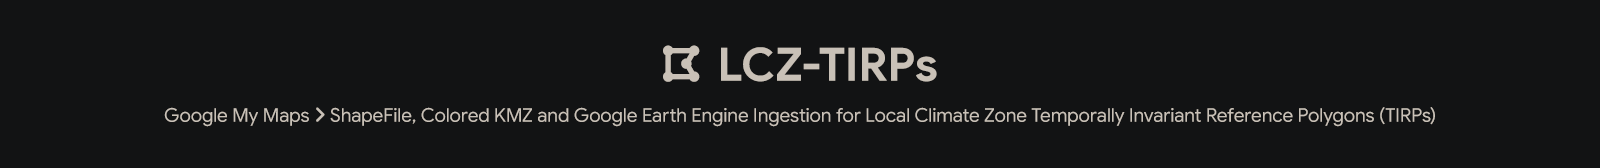

|||
|:--|:--|
| **Authors** | Ali Rezaali & Parastoo Pilehforooshha |
| **Code Archive** | Zenodo · [10.5281/zenodo.22865045](https://doi.org/10.5281/zenodo.22865045) |
| **Data Archive** | Zenodo · [10.5281/zenodo.22723885](https://doi.org/10.5281/zenodo.22723885) |
| **Notebook Version** | 1.0.0 |
| **Runtime** | Google Colab (Python 3) |

#### **How To Cite**

**UC4D (Code):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube Framework (Version 1.0) [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.22865045

**UC4D (Dataset):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube (Version 1.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.22723885

##### **Overview**

Digitizing Temporally Invariant Reference Polygons (TIRPs) for a Local Climate Zone classification is usually done in ArcGIS, QGIS or the GEE code editor, each asking for a licence, a desktop install, or a slow JavaScript polygon-drawing UI, limited imagery and more. **Google My Maps needs none of that**: it is free, runs in any browser, has Google's full historical high-resolution imagery for digitising past land cover, and anyone can be handed an edit link in seconds.

This notebook is the other half of that workflow: it takes what you drew in My Maps and turns it into the files a WUDAPT-style LCZ study actually needs, with nothing to install beyond `pip`.

```text
Google My Maps  →  KMZ export  →  This Notebook  →  Shapefile  (for QGIS / training)
                                                    →  Colored, sorted KMZ  (To Re-Check in Google My Maps / Google Earth)
                                                    →  Spatial-Independence CSV  (Nearest-Neighbour Distances)
                                                    →  Earth Engine Asset Ingestion  (For Sampling, Optional)
```

---

#### **How It Reads Your Map**

In "Google My Maps", draw one **layer per LCZ class** (*My Maps* calls them "*layers*"; KML calls them "*folders*") and name each layer or, if you prefer, each individual polygon with the class it represents: `1` … `10`, `A` … `G`, or `LCZ1` … `LCZG`, any of these are recognised. A polygon's own name wins if it matches one of these patterns; otherwise it inherits its layer's name. Anything that matches neither is skipped and listed, never guessed.

➜ Export: **My Maps → ⋮ (menu) → Export to KMZ → "Export all data as a single file"**, then put the KMZ where `KMZPath` (§2) expects it.

#### **Before You Begin**

[1] **Google My Maps Files**, one folder per city.

[2] **KMZ Per City**, exported as above.

[3] **Python Packages**: `geopandas`, `shapely`, `pyproj`, `simplekml` (installed in §1 if missing). No GDAL command-line tools, no ArcGIS Pro / QGIS needed.

[4] **Earth Engine (Optional, §9):** only needed if `EnableGEEIngestion = True`.

---

#### **[1] Environment**

In [10]:
# ———————————————
# [1] Environment
# ———————————————

try:

    from google.colab import drive

    drive.mount('/content/drive')

except ImportError:

    pass  # Not On Colab: Set DataRoot (§2) To A Local Folder.

import importlib.util

import subprocess

import sys

RequiredPackages = [ "geopandas" , "shapely" , "simplekml" ]

Missing          = [ Package for Package in RequiredPackages if importlib.util.find_spec(Package) is None ]

if Missing:

    subprocess.check_call([ sys.executable , "-m" , "pip" , "install" , "-q" , *Missing ])

import datetime

import platform

import re

import json

import warnings

import xml.etree.ElementTree as ElementTree

import zipfile

from importlib import metadata

from pathlib import Path

import geopandas as gpd

import numpy as np

import pandas as pd

import shapely

import simplekml

from IPython.display import display

from shapely.geometry import MultiPolygon, Polygon

warnings.filterwarnings( "ignore" , category = FutureWarning )

warnings.filterwarnings( "ignore" , category = UserWarning )

IsColab = "google.colab" in sys.modules

def PackageVersion(PackageName):

    try:

        return metadata.version(PackageName)

    except metadata.PackageNotFoundError:

        return "not installed"

print("Environment")

print("———————————")

WIDTH = 20

print(f"{'Run Started (UTC)':<{WIDTH}}: {datetime.datetime.now(datetime.timezone.utc):%Y-%m-%d %H:%M:%S}")

print(f"{'Platform':<{WIDTH}}: {'Google Colab' if IsColab else platform.platform()}")

print(f"{'Python':<{WIDTH}}: {platform.python_version()}")

for PackageName in ( "geopandas" , "shapely" , "pyproj" , "simplekml" , "pandas" , "numpy" ):

    print(f"{PackageName:<{WIDTH}}: {PackageVersion(PackageName)}")
    

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment
———————————
Run Started (UTC)   : 2026-11-03 18:55:19
Platform            : Google Colab
Python              : 3.13.18
geopandas           : 1.2.0
shapely             : 2.2.0
pyproj              : 3.8.0
simplekml           : 1.3.6
pandas              : 2.2.3
numpy               : 2.4.6


---

#### **[2] Configuration**

Everything city-specific lives here. `DataRoot` points to a folder in your mounted Google Drive (Colab). To run elsewhere, set it to any local folder.

In [11]:
# ——————————————————————
# [2] User Configuration
# ——————————————————————

# [2.1] Cities and Folders 

Cities   = [ "Tehran" , "Singapore" ]

DataRoot = Path("/content/drive/MyDrive/UC4D/LCZ-TIRPs") # A Google Drive folder (Colab). Use any local path when running elsewhere.

def CityPaths(City):

    """The Four Files This Notebook Reads Or Writes For One City."""

    Base = DataRoot / City

    return {

        "KMZ"       : Base / "01 KMZ" / f"{City}.kmz"                       ,

        "Shapefile" : Base / "02 SHP" / f"{City}.shp"                       ,

        "SortedKMZ" : Base / "03 KMZ (Sorted & Colored)" / f"{City}-SC.kmz" ,

        "StatsCSV"  : DataRoot / "LCZ-Spatial-Independence-Summary.csv"

    }


# [2.2] LCZ Class Recognition 

# A Folder Or Placemark Name Is Read As An LCZ Class If It Matches This Pattern Once An Optional Leading "LCZ" (any case) Is Stripped: One Or Two Digits (1-10), Or One Letter (A-G).

LCZNamePattern = re.compile(r"^(?:LCZ)?\s*(10|[1-9]|[A-Ga-g])$", re.IGNORECASE)

# [2.3] Earth Engine Ingestion (Optional, §9)

EnableGEEIngestion = False

GEEProject         = "ee-alirezaali"

GEEAssetRoot       = f"projects/{GEEProject}/assets/UC4D/Samples/LCZ"

def CityAssetPath(City):

    return f"{GEEAssetRoot}/{City}"

# ————————————————
# Derived Settings
# ————————————————

print(f"\nCities   : {', '.join(Cities)}\n")

print(f"DataRoot : {DataRoot.resolve()}\n")

print(f"GEE      : {'enabled → ' + GEEAssetRoot if EnableGEEIngestion else 'Disabled (Set EnableGEEIngestion = True To Turn On)'}")


Cities   : Tehran, Singapore

DataRoot : /content/drive/MyDrive/UC4D/LCZ-TIRPs

GEE      : Disabled (Set EnableGEEIngestion = True To Turn On)


---

#### **[3] LCZ Naming, Sorting and Color**

Three helpers that every later section builds on: normalise a matched name to a canonical LCZ<label> ID, sort IDs the way an LCZ table is conventionally read (LCZ1 … LCZ10, then LCZA … LCZG), and look up each class's official color.

The palette is the one used by the [LCZ Generator](https://lcz-generator.rub.de) and WUDAPT (Demuzere et al., 2021, after Stewart & Oke, 2012, full reference at the end), reproduced here so the notebook has no dependency on an external module or project folder.

In [12]:
# ———————————————————————————————
# [3] LCZ Naming, Sorting & Color
# ———————————————————————————————

# [3.1] LCZ Color Palette 

LCZPalette = {

"LCZ1" : "#8C0000" , "LCZ2" : "#D10000" , "LCZ3" : "#FF0000" , "LCZ4"  : "#BF4D00" , "LCZ5" : "#FF6600" , "LCZ6" : "#FF9955" , "LCZ7" : "#FAEE05" , "LCZ8"  : "#BCBCBC"                     ,

"LCZ9" : "#FFCCAA" , "LCZ10": "#555555" , "LCZA" : "#006A00" , "LCZB" : "#00AA00" , "LCZC" : "#648525" , "LCZD"  : "#B9DB79" , "LCZE" : "#000000" , "LCZF" : "#FBF7AE" , "LCZG" : "#6A6AFF" ,

}

LCZDescription = {

    "LCZ1" : "Compact Highrise" , "LCZ2" : "Compact Midrise" , "LCZ3" : "Compact Lowrise" , "LCZ4" : "Open Highrise" , "LCZ5" : "Open Midrise" , "LCZ6" : "Open Lowrise" ,
    
    "LCZ7": "Lightweight Lowrise" , "LCZ8" : "Large Lowrise" , "LCZ9" : "Sparsely Built" , "LCZ10" : "Heavy Industry" , "LCZA" : "Dense Trees" , "LCZB" : "Scattered Trees" ,
   
    "LCZC" : "Bush, Scrub" , "LCZD": "Low Plants" , "LCZE": "Bare Rock or Paved" , "LCZF" : "Bare Soil or Sand" , "LCZG" : "Water"

}


# [3.2] Name → LCZ ID

def MatchLCZName(RawName):

    """Return The 'LCZ<label>' ID For a Raw Folder / Placemark Name, or None If It Does Not Match."""

    Match = LCZNamePattern.match((RawName or "").strip())

    return None if Match is None else "LCZ" + Match.group(1).upper()


# [3.3] Sorting

def LCZSortKey(LCZID):

    """Sort Key: LCZ1 … LCZ10 Numerically, then LCZA … LCZG Alphabetically."""

    Label = str(LCZID)[3:]

    return (0, int(Label)) if Label.isdigit() else (1, Label)


# [3.4] Color & Description Lookups

def LCZColor(LCZID):

    Color = LCZPalette.get(LCZID)

    if Color is None:

        raise KeyError(f"'{LCZID}' is Not a Recognised LCZ Class (Expected LCZ1–LCZ10 or LCZA–LCZG).")

    return Color


def KMLColor(HexColor):

    """Convert '#RRGGBB' to KML's 'AABBGGRR' Order, Fully Opaque."""

    HexColor = HexColor.lstrip("#")

    return "ff" + HexColor[4:6] + HexColor[2:4] + HexColor[0:2]


PaletteTable = pd.DataFrame([ {"LCZID" : LCZID , "Description" : LCZDescription[LCZID] , "Color" : Color}
                      
                            for LCZID , Color in sorted(LCZPalette.items() , key = lambda Item: LCZSortKey(Item[0]))])

display(PaletteTable)

,LCZID,Description,Color
0,LCZ1,Compact Highrise,#8C0000
1,LCZ2,Compact Midrise,#D10000
2,LCZ3,Compact Lowrise,#FF0000
3,LCZ4,Open Highrise,#BF4D00
4,LCZ5,Open Midrise,#FF6600
5,LCZ6,Open Lowrise,#FF9955
6,LCZ7,Lightweight Lowrise,#FAEE05
7,LCZ8,Large Lowrise,#BCBCBC
8,LCZ9,Sparsely Built,#FFCCAA
9,LCZ10,Heavy Industry,#555555


---

#### **[4] Reading a KMZ**

A KMZ is a zipped KML. This parser walks every `<Folder>` and `<Placemark>` regardless of how deeply they are nested — "Google My Maps" sometimes adds an extra wrapper folder, and resolves each placemark's class with its own name first, then its parent folder's. It reads `Polygon` and `MultiGeometry` geometries (points and lines are not expected for TIRPs and are skipped with a note) and always drops altitude, since TIRPs are 2-D ground polygons.

It depends on nothing but the standard library's XML parser, so it reads a KMZ exactly as exported from Google My Maps or Google Earth.

In [13]:
# ———————————————
# [4] KMZ Reading
# ———————————————

def LocalTag(Element):

    """Strip a KML Namespace Off an Element Tag ('{http://...}Folder' -> 'Folder')."""

    return Element.tag.rsplit("}", 1)[-1]


def ParseCoordinates(Text):

    """Parse a KML <coordinates> Block Into a List Of (lon, lat), Dropping Altitude."""

    Points = []

    for Token in Text.split():

        Parts = Token.split(",")

        if len(Parts) >= 2:

            Points.append((float(Parts[0]), float(Parts[1])))

    return Points


def ParsePolygonElement(PolygonElement):

    """Build a shapely Polygon From a KML <Polygon> (Outer Boundary Plus Any Holes)."""

    Shell , Holes = None , []

    for Child in PolygonElement.iter():

        Tag = LocalTag(Child)

        if Tag not in ( "outerBoundaryIs" , "innerBoundaryIs" ):

            continue

        CoordsElement = next((C for C in Child.iter() if LocalTag(C) == "coordinates"), None)

        if CoordsElement is None or not (CoordsElement.text or "").strip():

            continue

        Ring = ParseCoordinates(CoordsElement.text)

        if Tag == "outerBoundaryIs":

            Shell = Ring

        else:

            Holes.append(Ring)

    return None if Shell is None or len(Shell) < 3 else Polygon(Shell, holes=Holes or None)


def ParseGeometryElement(Element):

    """Build a shapely Geometry From a KML <Polygon> or <MultiGeometry> | None For Unsupported Types (points, lines)."""

    Tag = LocalTag(Element)

    if Tag == "Polygon":

        return ParsePolygonElement(Element)

    if Tag == "MultiGeometry":

        Polygons = [ Polygon for Child in Element if LocalTag(Child) == "Polygon"

                   for Polygon in [ ParsePolygonElement(Child) ] if Polygon is not None]

        if not Polygons:

            return None

        return Polygons[0] if len(Polygons) == 1 else MultiPolygon(Polygons)

    return None


def ReadPlacemarksRecursive(Element, InheritedLCZID, SkippedNames):

    """Yield (LCZID, shapely geometry) For Every Placemark Under Element, Recursing Through Folders / Documents.

    InheritedLCZID Carries The Nearest Matched LCZ Class Down The Folder Tree.
    An Intermediate Sub-Folder (e.g. "Polygons" Inside "LCZ1") Does Not Override It.
    """

    Tag = LocalTag(Element)

    if Tag != "Placemark":

        # Any Other Container (KML, Document, Folder, ...) Is Just Walked Through.

        NameElement = next((C for C in Element if LocalTag(C) == "name"), None) if Tag in ("Document", "Folder") else None

        FolderName  = (NameElement.text or "").strip() if NameElement is not None and NameElement.text else ""

        FolderLCZID = MatchLCZName(FolderName) or InheritedLCZID

        for Child in Element:

            yield from ReadPlacemarksRecursive( Child , FolderLCZID , SkippedNames )

        return

    NameElement = next((C for C in Element if LocalTag(C) == "name"), None)

    OwnName = (NameElement.text or "").strip() if NameElement is not None and NameElement.text else ""

    LCZID = MatchLCZName(OwnName) or InheritedLCZID

    GeometryElement = next((C for C in Element if LocalTag(C) in ("Polygon", "MultiGeometry", "Point", "LineString")), None)

    if LCZID is None:

        SkippedNames.append(OwnName or InheritedLCZID or "(unnamed)")

        return

    if GeometryElement is None or LocalTag(GeometryElement) not in ("Polygon", "MultiGeometry"):

        SkippedNames.append(f"{OwnName or InheritedLCZID} (No Polygon Geometry)")

        return

    Geometry = ParseGeometryElement(GeometryElement)

    if Geometry is None or Geometry.is_empty or not Geometry.is_valid:

        SkippedNames.append(f"{OwnName or InheritedLCZID} (Invalid or Empty Polygon)")

        return

    yield LCZID, Geometry


def ReadLCZFeaturesFromKMZ(KMZPath):

    """Return (features, skipped) For One KMZ: Features Is a List Of (LCZID, shapely geometry); Skipped Lists Raw Names That Matched No LCZ Class."""

    KMZPath = Path(KMZPath)

    if not KMZPath.exists():

        raise FileNotFoundError(f"KMZ Not Found: {KMZPath}")

    with zipfile.ZipFile( KMZPath , "r" ) as Archive:

        KMLNames = [ Name for Name in Archive.namelist() if Name.lower().endswith(".kml") ]

        if not KMLNames:

            raise FileNotFoundError(f"No .kml Inside {KMZPath}")

        KMLBytes = Archive.read(KMLNames[0])

    Root = ElementTree.fromstring(KMLBytes)

    Skipped = []

    Features = list(ReadPlacemarksRecursive( Root , None , Skipped ))

    if not Features:

        raise ValueError(f"No LCZ Polygons Recognised In {KMZPath}. Check Layer / Placemark Names Against The Pattern In §2.2.")

    Features.sort( key = lambda Item: LCZSortKey(Item[0]))

    return Features , Skipped

---

#### **[5] Writing the Outputs** 

Two exports, from the same `(LCZID, geometry)` list that §4 produced:

[1] **Shapefile** — one `LCZID` text field, for anything that reads a shapefile (QGIS, an ML training script, GEE's shapefile importer).

[2] **Sorted, Colored KMZ** — the same features, reordered `LCZ1 → LCZ10 → LCZA → LCZG`, with each placemark's name and its official WUDAPT fill/outline Color (§3) set with `simplekml`, so opening it in Google Earth or re-importing it into My Maps immediately shows a correctly Colored, correctly ordered legend — a quick visual check that nothing was mis-digitised or mis-named.

In [14]:
# ——————————
# [5] Export
# ——————————

# [5.1] Shapefile 

def WriteShapefile( Features , OutPath ):

    """Write (LCZID, geometry) Pairs As a Shapefile With One 'LCZID' Field."""

    OutPath = Path(OutPath)

    OutPath.parent.mkdir( parents = True , exist_ok = True )

    GeoDataFrame = gpd.GeoDataFrame({ "LCZID" : [ LCZID for LCZID , _ in Features ]} , geometry = [ Geometry for _ , Geometry in Features ] , crs = "EPSG:4326" )

    GeoDataFrame.to_file( OutPath , driver = "ESRI Shapefile" )

    return GeoDataFrame


# [5.2] Sorted, Colored KMZ 

def AddPolygonToKML( KML , LCZID , Geometry ):

    """Add One Feature's Geometry To a simplekml Document as a (multi)Polygon Placemark, Styled by LCZ Color."""

    Color    = KMLColor(LCZColor(LCZID))

    Polygons = Geometry.geoms if Geometry.geom_type == "MultiPolygon" else [ Geometry ]

    if len(Polygons) == 1:

        Placemark                 = KML.newpolygon(name=LCZID)

        Placemark.outerboundaryis = list(Polygons[0].exterior.coords)

        Placemark.innerboundaryis = [ list(Ring.coords) for Ring in Polygons[0].interiors ]

    else:

        Placemark = KML.newmultigeometry(name=LCZID)

        for SinglePolygon in Polygons:

            Part                 = Placemark.newpolygon()

            Part.outerboundaryis = list(SinglePolygon.exterior.coords)

            Part.innerboundaryis = [ list(Ring.coords) for Ring in SinglePolygon.interiors ]

    Placemark.style.linestyle.color   = Color

    Placemark.style.linestyle.width   = 2

    Placemark.style.polystyle.color   = Color

    Placemark.style.polystyle.fill    = 1

    Placemark.style.polystyle.outline = 1

    return Placemark


def WriteSortedColoredKMZ(Features, OutPath):

    """Write (LCZID, geometry) Pairs, Already Sorted, As a Single Colored KMZ."""

    OutPath = Path(OutPath)

    OutPath.parent.mkdir( parents = True , exist_ok = True )

    KML = simplekml.Kml( name = OutPath.stem )

    for LCZID , Geometry in Features:

        AddPolygonToKML( KML , LCZID , Geometry )

    KML.savekmz(str(OutPath))

---

#### **[6] Batch Pipeline** 

For every city: read the KMZ, report what was found (and what was skipped) **before** writing anything, then write the shapefile and the colored KMZ.

In [15]:
# ——————————————————
# [6] Batch Pipeline
# ——————————————————

def SummariseFeatures(Features, Skipped, City):

    """Print a per-class feature count, and any names that could not be matched to an LCZ class."""

    Counts = pd.Series([ LCZID for LCZID , _ in Features ]).value_counts()

    Table = pd.DataFrame({ "LCZID" : Counts.index , "Description" : [ LCZDescription[I] for I in Counts.index ] , "Count" : Counts.values })

    Table = Table.sort_values( "LCZID" , key = lambda Col : Col.map(LCZSortKey)).reset_index( drop = True )

    print(f"\n{City} : {len(Features)} Features Across {len(Table)} Classes")

    display(Table)

    if Skipped:

        print(f"⚠️  {len(Skipped)} Feature(s) Did Not Match An LCZ Class (Or Had An Invalid Polygon) And Were Skipped: {Skipped}")
      
        print("   Rename The Layer Or Placemark In Google My Maps To One Of LCZ1–LCZ10 / LCZA–LCZG, Re-export, And Re-run.")


def ProcessCity(City):

    """Read a City's KMZ, Report Its Contents, and Write The Shapefile and Colored KMZ."""

    Paths              = CityPaths(City)

    Features , Skipped = ReadLCZFeaturesFromKMZ(Paths["KMZ"])

    SummariseFeatures( Features , Skipped , City )

    WriteShapefile( Features , Paths["Shapefile"] )

    WriteSortedColoredKMZ( Features , Paths["SortedKMZ"] )

    print(f"✅ {City} Written:\n")

    print(f"   Shapefile : {Paths['Shapefile']}\n")

    print(f"   KMZ       : {Paths['SortedKMZ']}")

    return Features

CityFeatures = { City : ProcessCity(City) for City in Cities }


Tehran : 371 Features Across 17 Classes


,LCZID,Description,Count
0,LCZ1,Compact Highrise,30
1,LCZ2,Compact Midrise,29
2,LCZ3,Compact Lowrise,22
3,LCZ4,Open Highrise,17
4,LCZ5,Open Midrise,33
5,LCZ6,Open Lowrise,11
6,LCZ7,Lightweight Lowrise,31
7,LCZ8,Large Lowrise,23
8,LCZ9,Sparsely Built,40
9,LCZ10,Heavy Industry,11


✅ Tehran Written:

   Shapefile : /content/drive/MyDrive/UC4D/LCZ-TIRPs/Tehran/02 SHP/Tehran.shp

   KMZ       : /content/drive/MyDrive/UC4D/LCZ-TIRPs/Tehran/03 KMZ (Sorted & Colored)/Tehran-SC.kmz

Singapore : 413 Features Across 16 Classes


,LCZID,Description,Count
0,LCZ1,Compact Highrise,12
1,LCZ2,Compact Midrise,38
2,LCZ3,Compact Lowrise,31
3,LCZ4,Open Highrise,24
4,LCZ5,Open Midrise,42
5,LCZ6,Open Lowrise,28
6,LCZ8,Large Lowrise,35
7,LCZ9,Sparsely Built,36
8,LCZ10,Heavy Industry,20
9,LCZA,Dense Trees,16


✅ Singapore Written:

   Shapefile : /content/drive/MyDrive/UC4D/LCZ-TIRPs/Singapore/02 SHP/Singapore.shp

   KMZ       : /content/drive/MyDrive/UC4D/LCZ-TIRPs/Singapore/03 KMZ (Sorted & Colored)/Singapore-SC.kmz


---

#### **[7]  Spatial-Independence Statistics**

For a classifier's accuracy to mean anything, the polygons used for training and for holding out must be far enough apart that they are not effectively the same patch of city sampled twice. For every LCZ class this computes the full set of pairwise polygon-to-polygon distances (boundary to boundary, not centroid to centroid) and, from the same matrix, each polygon's distance to its single **nearest neighbour**, the one number that most directly answers "how close are the two nearest samples of this class?". Everything is computed in the dataset's local UTM zone, in metres, then reported in kilometres.

A class with only one polygon has no pairwise distance to report and is noted, not dropped or zero-filled, a true `0` would wrongly read as "touching."

In [16]:
# ———————————————————————————————————
# [7] Spatial-Independence Statistics
# ———————————————————————————————————

# [7.1] Local Metric Projection 

def EstimateUTMEPSG(GeoDataFrame):

    """EPSG Code Of The UTM Zone Covering a GeoDataFrame's Centroid, For Metre-accurate Distances."""

    Centroid = GeoDataFrame.union_all().centroid if hasattr( GeoDataFrame , "union_all" ) else GeoDataFrame.unary_union.centroid

    Zone = int((Centroid.x + 180) // 6) + 1

    return (32600 if Centroid.y >= 0 else 32700) + Zone


# [7.2] Pairwise and Nearest-Neighbour Distances 

LargeClassWarningSize = 1500

def ComputeClassDistanceStats(Polygons):

    """Pairwise and Nearest-Neighbour Distance Statistics (metres) For One LCZ Class's Polygons, Already In a Metric CRS."""

    N = len(Polygons)

    if N < 2:

        return { "Count" : N , "Note" : "Single Polygon" if N == 1 else "No Polygons"}

    if N > LargeClassWarningSize:

        print(f"   ⚠️  {N} Polygons In One Class: The O(N²) Distance Matrix Has {N * N:,} Entries And May Take a While.")

    Geometries     = np.asarray( Polygons , dtype = object )

    DistanceMatrix = shapely.distance( Geometries[:, None] , Geometries[None, :] )

    UpperIndices   = np.triu_indices( N , k = 1 )

    PairwiseDists  = DistanceMatrix[UpperIndices]

    NoSelf         = DistanceMatrix.copy()

    np.fill_diagonal( NoSelf , np.inf )

    NearestNeighbourDists = NoSelf.min( axis = 1 )

    return {

        "Count"      : N                                                                   ,
       
        "Min"        : PairwiseDists.min()                                                 ,
       
        "Mean"       : PairwiseDists.mean()                                                ,
       
        "Max"        : PairwiseDists.max()                                                 ,
       
        "Std"        : PairwiseDists.std( ddof = 1 ) if len(PairwiseDists) > 1 else np.nan ,

        "Median"     : np.median(PairwiseDists)                                            ,
       
        "MeanNNDist" : NearestNeighbourDists.mean()                                        ,
       
        "MinNNDist"  : NearestNeighbourDists.min()

    }


def ComputeCityDistanceStats(GeoDataFrame, ClassField="LCZID"):

    """ComputeClassDistanceStats For Every LCZ Class Present In a City's GeoDataFrame."""

    EPSG = EstimateUTMEPSG(GeoDataFrame)

    Projected = GeoDataFrame.to_crs( epsg = EPSG )

    return {LCZID: ComputeClassDistanceStats(Group.geometry.tolist()) for LCZID, Group in Projected.groupby(ClassField)} , EPSG


# [7.3] Console Report

def PrintCityStats( City , Stats , EPSG ):

    Width = 92

    print(f"\n{'—' * Width}\n  {City} · Inter-polygon Distances (UTM EPSG:{EPSG}, metres)\n{'—' * Width}")

    Header = f"{'LCZID':<7}{'Count':>6}{'Min':>10}{'Mean':>10}{'Max':>10}{'Std':>10}{'Median':>10}{'MeanNN':>10}{'MinNN':>10}"

    print(Header); print("—" * Width)

    for LCZID in sorted( Stats , key = LCZSortKey ):

        S = Stats[LCZID]

        if "Note" in S:

            print(f"{LCZID:<7}{S['Count']:>6}   — {S['Note']} —")

        else:

            print(f"{LCZID:<7}{S['Count']:>6}{S['Min']:>10.1f}{S['Mean']:>10.1f}{S['Max']:>10.1f}"
                
                  f"{S['Std']:>10.1f}{S['Median']:>10.1f}{S['MeanNNDist']:>10.1f}{S['MinNNDist']:>10.1f}")

    print("—" * Width)

---

#### **[8] Run the Statistics and Export the Summary**

One consolidated CSV across every city, matching the convention used elsewhere in this study: one row per LCZ class, columns named `<City><Metric>KM`. Distance metrics are left blank for any class a city has fewer than two polygons for (or does not have at all); the polygon count is preserved.

In [17]:
# ————————————————
# [8] Run & Export
# ————————————————

MetricsToReport = { "Count" : None , "MinGap" : "Min" , "PairwiseMean" : "Mean" , "PairwiseMedian" : "Median" , "MeanNNDistance" : "MeanNNDist" , "MinNNDistance" : "MinNNDist" }

def ExportConsolidatedCSV( CityStats , OutPath ):

    """One Row Per LCZ Class, '<City><Metric>KM' Columns (Distances In km; 'Count' Unitless). Missing / Single-Polygon Classes Are Blank."""

    AllClasses = sorted({LCZID for Stats in CityStats.values() for LCZID in Stats}, key=LCZSortKey)

    Rows = []

    for LCZID in AllClasses:

        Row = { "LCZClass" : LCZID , "Description" : LCZDescription[LCZID] }

        for City , Stats in CityStats.items():

            ClassStats   = Stats.get(LCZID, {})

            HasStats     = bool(ClassStats)

            HasDistances = HasStats and "Note" not in ClassStats

            for Column, SourceKey in MetricsToReport.items():

                ColumnName = f"{City}{Column}" + ("" if Column == "Count" else "KM")

                if not HasStats:

                    Row[ColumnName] = None

                elif Column == "Count":

                    Row[ColumnName] = ClassStats["Count"]

                elif not HasDistances:

                    Row[ColumnName] = None

                else:

                    Row[ColumnName] = round(ClassStats[SourceKey] / 1000, 3)

        Rows.append(Row)

    SummaryTable = pd.DataFrame(Rows)

    OutPath      = Path(OutPath)

    OutPath.parent.mkdir( parents = True , exist_ok = True )

    SummaryTable.to_csv( OutPath , index = False )

    print(f"\n✅ Consolidated Spatial-Independence Summary Saved To: {OutPath}")

    return SummaryTable


CityDistanceStats , CityGeoDataFrames = {} , {}

for City in Cities:

    GeoDataFrame = gpd.GeoDataFrame({"LCZID": [ L for L , _ in CityFeatures[City] ]} , geometry=[ G for _ , G in CityFeatures[City] ] , crs = "EPSG:4326")

    Stats , EPSG = ComputeCityDistanceStats(GeoDataFrame)

    PrintCityStats( City , Stats , EPSG )

    CityDistanceStats[City] , CityGeoDataFrames[City] = Stats , GeoDataFrame

SummaryTable = ExportConsolidatedCSV( CityDistanceStats , CityPaths(Cities[0])["StatsCSV"] )

display(SummaryTable)


————————————————————————————————————————————————————————————————————————————————————————————
  Tehran · Inter-polygon Distances (UTM EPSG:32639, metres)
————————————————————————————————————————————————————————————————————————————————————————————
LCZID   Count       Min      Mean       Max       Std    Median    MeanNN     MinNN
————————————————————————————————————————————————————————————————————————————————————————————
LCZ1       30     118.1   17366.5   80789.6   14744.4   14128.9    2985.1     118.1
LCZ2       29     420.7   14909.6   51189.1   11173.9   11799.6    1630.7     420.7
LCZ3       22     263.3   19768.0   53738.0   11772.4   17866.0    2226.7     263.3
LCZ4       17     171.0    9366.4   21996.3    7073.3    8080.3    1109.6     171.0
LCZ5       33     159.6   12318.3   30251.2    6676.7   13440.7    1102.8     159.6
LCZ6       11     223.7   30643.6   62619.6   23906.1   41998.1    1976.5     223.7
LCZ7       31     117.8   18608.0   59977.7   11073.4   18024.3    2645.

,LCZClass,Description,TehranCount,TehranMinGapKM,TehranPairwiseMeanKM,TehranPairwiseMedianKM,TehranMeanNNDistanceKM,TehranMinNNDistanceKM,SingaporeCount,SingaporeMinGapKM,SingaporePairwiseMeanKM,SingaporePairwiseMedianKM,SingaporeMeanNNDistanceKM,SingaporeMinNNDistanceKM
0,LCZ1,Compact Highrise,30,0.118,17.367,14.129,2.985,0.118,12.0,0.109,7.195,0.991,1.328,0.109
1,LCZ2,Compact Midrise,29,0.421,14.910,11.800,1.631,0.421,38.0,0.147,10.087,9.177,1.009,0.147
2,LCZ3,Compact Lowrise,22,0.263,19.768,17.866,2.227,0.263,31.0,0.116,18.101,18.883,0.967,0.116
3,LCZ4,Open Highrise,17,0.171,9.366,8.080,1.110,0.171,24.0,0.142,9.725,12.967,1.133,0.142
4,LCZ5,Open Midrise,33,0.160,12.318,13.441,1.103,0.160,42.0,0.099,8.718,8.518,0.759,0.099
5,LCZ6,Open Lowrise,11,0.224,30.644,41.998,1.977,0.224,28.0,0.105,8.259,8.751,1.020,0.105
6,LCZ7,Lightweight Lowrise,31,0.118,18.608,18.024,2.645,0.118,NaN,NaN,NaN,NaN,NaN,NaN
7,LCZ8,Large Lowrise,23,0.143,20.859,26.180,3.128,0.143,35.0,0.144,12.500,12.366,1.516,0.144
8,LCZ9,Sparsely Built,40,0.132,27.319,29.903,2.222,0.132,36.0,0.116,14.791,14.667,1.073,0.116
9,LCZ10,Heavy Industry,11,0.167,20.191,21.237,2.428,0.167,20.0,0.316,12.325,7.715,3.118,0.316


---

#### **[9] Earth Engine Ingestion (Optional)**

Off by default (`EnableGEEIngestion` in §2). When turned on, each city's shapefile is uploaded as a `FeatureCollection` asset at `CityAssetPath(City)`. Geometries are repaired (`buffer(0)`) and flattened to 2-D, and missing attributes are blanked rather than left as `NaN`, which the Earth Engine client cannot send as JSON.

For each city, if the target asset already exists, the notebook asks once before deleting and re-uploading it; otherwise it uploads directly. Missing assets never require confirmation.

In [18]:
# ——————————————————————————
# [9] Earth Engine Ingestion
# ——————————————————————————

if EnableGEEIngestion:

    import ee

    from shapely.ops import transform as ShapelyTransform

    # [9.1] Session

    def InitializeEarthEngine():

        try:

            ee.Initialize( project = GEEProject )

        except Exception:

            print("Earth Engine Sign-in Required. Follow The Prompt…")

            ee.Authenticate()

            ee.Initialize( project = GEEProject )

        print(f"\n✅ Earth Engine Initialised (Project : {GEEProject}).")

    InitializeEarthEngine()

    # [9.2] Sanitization for the GEE Client

    def SanitizeForEarthEngine(GeoDataFrame):

        """Drop Empty Geometries, Force 2D, Repair Invalid Rings, And Blank NaNs (GEE's JSON Parser Rejects Them)."""

        Clean = GeoDataFrame[GeoDataFrame.geometry.notna() & ~GeoDataFrame.is_empty].copy()

        Clean["geometry"] = (Clean["geometry"].apply(shapely.force_2d) if hasattr(shapely, "force_2d")
                           
                             else Clean["geometry"].apply(lambda G: ShapelyTransform(lambda x , y , *z: (x, y) , G )))

        Clean["geometry"] = Clean["geometry"].buffer(0)

        return Clean.fillna("")

    # [9.3] Existing-Asset Check & Confirmation

    def EnsureGEEFolder(AssetPath):
    
        Prefix  = f"projects/{GEEProject}/assets/"
    
        Current = Prefix.rstrip("/")
    
        for Part in AssetPath[len(Prefix):].strip("/").split("/"):
    
            Current = f"{Current}/{Part}"
    
            try:
    
                ee.data.getAsset(Current)
    
            except ee.EEException:
    
                ee.data.createAsset({ "type" : "FOLDER" } , Current )
    
    def AssetExists(AssetPath):

        try:

            ee.data.getAsset(AssetPath)

            return True

        except ee.EEException:

            return False

    def ConfirmOverwrites(AssetPaths):

        """Ask About Only The Assets That Already Exist. Returns The Set That Is Clear To Upload To."""

        Existing = [ Path for Path in AssetPaths if AssetExists(Path) ]

        if not Existing:

            return set(AssetPaths)

        print("\nThese Assets Already Exist And Would Be OVERWRITTEN:\n")

        for Path in Existing:

            print(f"  - {Path}\n")

        Confirmed = input(f"\nType 'YES' To Delete And Replace These {len(Existing)} Asset(s); Anything Else Skips Them: ").strip()

        if Confirmed != "YES":

            print("\nSkipping The Existing Assets Above; New Assets Are Still Uploaded.")

            return set(AssetPaths) - set(Existing)

        for Path in Existing:

            ee.data.deleteAsset(Path)

            print(f"\n  🗑️  Deleted {Path}")

        return set(AssetPaths)

    # [9.4] Upload 

    def UploadCityToEarthEngine(City, GeoDataFrame, AssetPath):

        Clean             = SanitizeForEarthEngine(GeoDataFrame)

        FeatureCollection = ee.FeatureCollection(json.loads(Clean.to_json()))

        Task              = ee.batch.Export.table.toAsset( collection = FeatureCollection , description = f"{City}-LCZ-Ingest" , assetId = AssetPath )

        Task.start()

        print(f"\n   📤 {City}: Upload Task Started ({len(Clean)} Features) → {AssetPath} (Task ID {Task.id})")

        return Task

    # [9.5] Run 
    
    EnsureGEEFolder(GEEAssetRoot)
    
    TargetAssets   = {City: CityAssetPath(City) for City in Cities}

    ClearToUpload  = ConfirmOverwrites(list(TargetAssets.values()))

    IngestionTasks = {City: UploadCityToEarthEngine(City, CityGeoDataFrames[City], AssetPath)
                  
                      for City, AssetPath in TargetAssets.items() if AssetPath in ClearToUpload}

    print(f"\n{len(IngestionTasks)} Of {len(Cities)} Cities Submitted. Tasks Finish In The Background; See §10 To Confirm.")

else:

    print("Earth Engine Ingestion Is Disabled (EnableGEEIngestion = False In §2). Skipping §9.")

Earth Engine Ingestion Is Disabled (EnableGEEIngestion = False In §2). Skipping §9.


---

#### **[10]   Verification**

Confirms that each shapefile's feature count matches what was read from its KMZ, and, only if §9 ran, that the Earth Engine asset exists and holds the same number of features.

In [19]:
# —————————————————
# [10] Verification
# —————————————————

def VerifyShapefile(City):

    Paths    = CityPaths(City)

    Expected = len(CityFeatures[City])

    Written  = len(gpd.read_file(Paths["Shapefile"]))

    return Expected , Written


Rows = []

for City in Cities:

    Expected , Written = VerifyShapefile(City)

    Row = { "City" : City , "Features (Read From KMZ)" : Expected , "Features (In Shapefile)" : Written , "Shapefile OK" : "✅" if Expected == Written else "❌"}

    if EnableGEEIngestion:

        AssetPath = CityAssetPath(City)

        try:

            AssetSize = ee.data.getAsset(AssetPath).get("featureCount") or len(ee.FeatureCollection(AssetPath).aggregate_array("LCZID").getInfo())

            Row["GEE Asset"] = "✅" if AssetSize == Expected else f"⏳ {AssetSize} of {Expected} Visible So Far"

        except Exception:

            Row["GEE Asset"] = "⏳ Ingestion Tasks Running In The Background"

    Rows.append(Row)

display(pd.DataFrame(Rows))

,City,Features (Read From KMZ),Features (In Shapefile),Shapefile OK
0,Tehran,371,371,✅
1,Singapore,413,413,✅


---

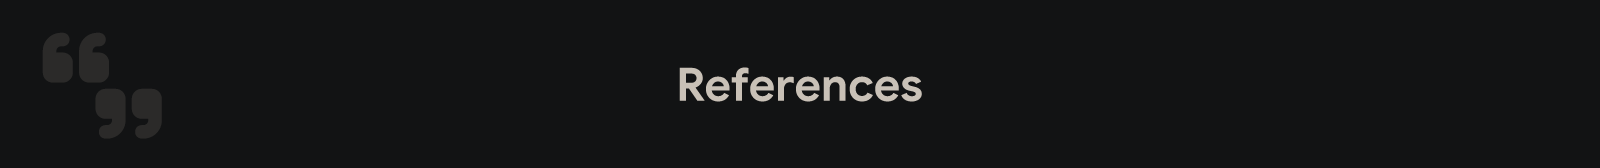

**[1] Local Climate Zone Scheme**

-  Stewart, I. D., & Oke, T. R. (2012). Local Climate Zones for Urban Temperature Studies. *Bulletin of the American Meteorological Society, 93*(12), 1879–1900. https://doi.org/10.1175/BAMS-D-11-00019.1

- Demuzere, M., Kittner, J., & Bechtel, B. (2021). LCZ Generator: A Web Application to Create Local Climate Zone Maps. *Frontiers in Environmental Science, 9*, 637455. https://doi.org/10.3389/fenvs.2021.637455

**[2] Software**

- Lancaster, K., & Eisoldt, P. *simplekml* [Software]. https://pypi.org/project/simplekml/

- Gorelick, N., Hancher, M., Dixon, M., Ilyushchenko, S., Thau, D., Moore, R., 2017. Google Earth Engine: Planetary-scale geospatial analysis for everyone. Remote Sens. Environ. 202, 18–27. https://doi.org/10.1016/j.rse.2017.06.031

- Jordahl, K., Van den Bossche, J., Fleischmann, M., et al. *GeoPandas* [Software]. https://geopandas.org

- Gillies, S., et al. *Shapely* [Software]. https://shapely.readthedocs.io

**[3] Digitizing Tool**

- Google My Maps. https://www.google.com/maps/d/ | Used here only as a free, browser-based polygon editor over Google's historical high-resolution imagery; not a source of the LCZ scheme itself.